# 02b — Composition deep dive: what is actually driving the differences between these tumours?

`02` ran every pairwise comparison and found few RT hits and many CAR-target hits. This notebook
stops testing pairs and asks the structural questions instead — the ones that explain *why* the
pairwise table looks the way it does.

| § | Question | Method |
|---|---|---|
| 2 | **How much of the variation does each experimental factor explain?** | variance decomposition per cell type |
| 3 | **Do samples cluster by CAR target, by radiation, or by neither?** | Aitchison PCA + PERMANOVA |
| 4 | **Does RT do different things in the two CAR backgrounds?** | the `cart x RT` interaction, plotted |
| 5 | Every comparison for every cell type, at a glance | 10 x 10 log2FC heatmaps |
| 6 | Which cell type moved in which comparison | volcano plots |
| 7 | Every animal, every cell type | per-mouse Tu1 -> Tu2 small multiples |
| 8 | The one RT lead, from every angle | `M1_like_Mac` deep dive |
| 9 | Which populations move together? | cell-type co-variation |
| 10 | How big is an RT effect compared with the other axes? | effect-size distributions by contrast type |
| 11 | Is any of it a sequencing-depth artifact? | equal-depth downsampling |

`NoTx` appears only where it is labelled as a scale reference. Every inferential statement is
treated-vs-treated.

## 1. Config and load

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import itertools
import numpy as np, pandas as pd, h5py, anndata as ad
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import statsmodels.api as sm, statsmodels.formula.api as smf

pd.set_option("display.width", 320); pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 500)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _HPC if _HPC.exists() else _LOC
SC_REF = (PROJ/"data/zarr/fullDataset/annotating_references/annotation_v4.h5ad"
          if PROJ is _HPC else PROJ/"data/sc-reference/annotation_v4.h5ad")
OUT = PROJ/"results/rt_advantage"; FIG = OUT/"figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

PSEUDO, SEED = 0.5, 0
rng = np.random.default_rng(SEED)
ARM_ORDER = ["NoTx", "CyPSCA", "RTCyPSCA", "CyTAG72", "RTCyTAG72"]
COL = {"NoTx": "#8d8d8d", "CyPSCA": "#3b6ea5", "RTCyPSCA": "#d1495b",
       "CyTAG72": "#7fb069", "RTCyTAG72": "#e8a33d"}

with h5py.File(SC_REF, "r") as f:
    o = ad.io.read_elem(f["obs"])
o["sample"] = o["file_name"].astype(str)
p = o["sample"].str.extract(r"^(?P<arm>.+)_Tu(?P<site>\d)_(?P<rep>\d+)$")
o["arm"], o["site"] = p["arm"], p["site"].astype(int)
o["mouse"] = p["arm"] + "_m" + p["rep"]
o["ct"] = o["cell_type_lvl2"].astype(str)

cnt  = pd.crosstab(o["sample"], o["ct"]).drop(columns=["Erythrocyte"], errors="ignore")
meta = o.groupby("sample", observed=True).agg(arm=("arm","first"), site=("site","first"),
                                              mouse=("mouse","first"))
meta["grp"]  = meta.arm + "_Tu" + meta.site.astype(str)
meta["cart"] = meta.arm.str.replace(r"^RTCy", "", regex=True).str.replace(r"^Cy", "", regex=True)
meta["RT"]   = meta.arm.str.startswith("RT")
cnt = cnt.reindex(meta.index)
prop = cnt.div(cnt.sum(1), axis=0)
x = cnt.values.astype(float) + PSEUDO
lg = np.log(x / x.sum(1, keepdims=True))
CLR = pd.DataFrame(lg - lg.mean(1, keepdims=True), index=cnt.index, columns=cnt.columns)
CTS = list(cnt.columns)
TREATED = meta.index[meta.arm != "NoTx"]
print(f"{len(cnt)} samples, {len(CTS)} cell types, {len(TREATED)} treated")
print(meta.groupby(["cart","RT","site"]).size().to_string())

29 samples, 18 cell types, 23 treated
cart   RT     site
NoTx   False  1       3
              2       3
PSCA   False  1       3
              2       3
       True   1       3
              2       3
TAG72  False  1       2
              2       3
       True   1       3
              2       3


## 2. Variance decomposition — the single most informative number in this notebook

For each cell type, a linear model on the CLR value across the **23 treated samples**:

```
CLR ~ CAR target  +  RT  +  tumour site  +  (CAR target x RT)
```

and the percentage of total variance each term accounts for. Residual is everything left —
mostly animal-to-animal variation, which is the thing that makes n = 3 hard.

Read the `cart` column against the `RT` column. If `cart` is large and `RT` is small, the
composition is tracking **which CAR was given**, and radiation is a minor term.

In [2]:
T = CLR.loc[TREATED].join(meta)
rows = []
for ct in CTS:
    d = T.rename(columns={ct: "y"})[["y", "cart", "RT", "site"]]
    m = smf.ols("y ~ C(cart) + C(RT) + C(site) + C(cart):C(RT)", data=d).fit()
    a = sm.stats.anova_lm(m, typ=2)
    tot = a["sum_sq"].sum()
    rows.append(dict(cell_type=ct, r2=m.rsquared,
                     **{k.replace("C(", "").replace(")", "").replace(":", " x "): 100*v/tot
                        for k, v in a["sum_sq"].items()}))
V = (pd.DataFrame(rows).set_index("cell_type")
       .rename(columns={"Residual": "residual (mouse-to-mouse)"}))
V["median_cells"] = cnt.median(0)
V = V.sort_values("cart", ascending=False)
V.to_csv(OUT/"variance_decomposition.csv")
print("VARIANCE EXPLAINED (%), treated samples only")
print(V.round(1).to_string())
print("\nmean across all cell types:")
print(V[["cart","RT","site","cart x RT","residual (mouse-to-mouse)"]].mean().round(1).to_string())
print("\nweighted by abundance (cell types with >=100 cells in the median sample):")
big = V[V.median_cells >= 100]
print(big[["cart","RT","site","cart x RT","residual (mouse-to-mouse)"]].mean().round(1).to_string())

VARIANCE EXPLAINED (%), treated samples only
                    r2  cart    RT  site  cart x RT  residual (mouse-to-mouse)  median_cells
cell_type                                                                                   
M1_like_Mac        0.6  51.0   3.6   0.0        5.9                       39.5         479.0
M2_like_Mac        0.6  37.9   2.1   0.0       17.7                       42.3         704.0
Fibroblast         0.4  18.7   7.3   9.9        2.5                       61.6           5.0
CD4_T              0.4  17.8  10.3   2.5        9.0                       60.4           2.0
Nonclassical_Mono  0.2  13.0   0.0   2.8        0.3                       83.9         168.0
Endothelial        0.1  11.2   0.8   0.0        0.5                       87.5           6.0
CD8_T              0.3   6.2   0.4  16.4        4.5                       72.4          14.0
NK                 0.2   5.1   1.6  12.6        4.4                       76.3          32.0
Treg               0.3   

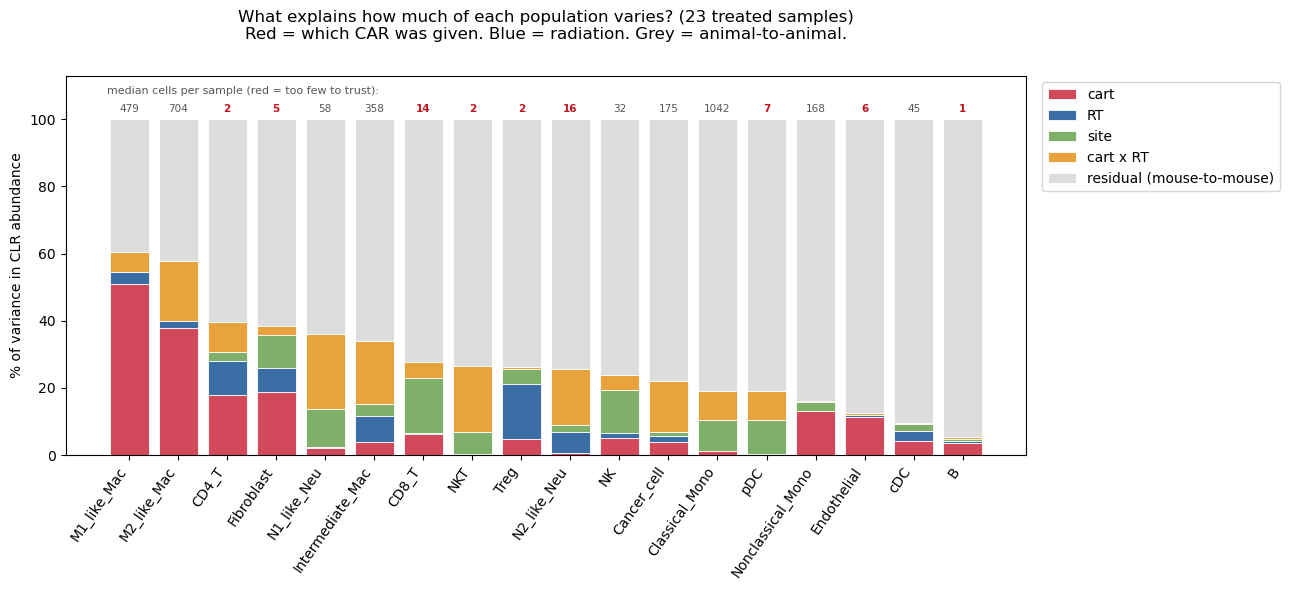

In [3]:
terms = ["cart", "RT", "site", "cart x RT", "residual (mouse-to-mouse)"]
cols  = ["#d1495b", "#3b6ea5", "#7fb069", "#e8a33d", "#dddddd"]
d = V[terms].loc[V[terms[:-1]].sum(1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 6))
bottom = np.zeros(len(d))
for t, c in zip(terms, cols):
    ax.bar(d.index, d[t], bottom=bottom, label=t, color=c, edgecolor="white", lw=.6)
    bottom += d[t].values
ax.set_ylabel("% of variance in CLR abundance"); ax.set_ylim(0, 113)
ax.tick_params(axis="x", rotation=55)
for lbl in ax.get_xticklabels(): lbl.set_ha("right")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("What explains how much of each population varies? (23 treated samples)\n"
             "Red = which CAR was given. Blue = radiation. Grey = animal-to-animal.",
             fontsize=12, pad=26)
for i, ctn in enumerate(d.index):
    n_ = int(V.loc[ctn, "median_cells"])
    ax.text(i, 102, f"{n_}", ha="center", fontsize=7.5,
            color="#555" if n_ >= 20 else "#c1121f",
            fontweight="normal" if n_ >= 20 else "bold")
ax.text(-0.45, 107.5, "median cells per sample (red = too few to trust):",
        fontsize=8, color="#555")
fig.tight_layout(); fig.savefig(FIG/"02b_variance_decomposition.png", dpi=250, bbox_inches="tight")
plt.show()

## 3. Do the samples cluster by CAR target, by radiation, or by neither?

Aitchison PCA (PCA on CLR) plus **PERMANOVA**, which tests whether a grouping explains more
between-sample distance than chance. Run twice: on all 29 samples, where the treatment effect
will dominate everything, and on the **23 treated samples**, which is the honest test.

In [4]:
def permanova(Dm, labels, n_perm=9999, seed=SEED):
    rg = np.random.default_rng(seed); labels = np.asarray(labels); n = len(labels)
    def F(l):
        SST = (Dm**2).sum()/(2*n); SSW = 0.0
        for g in np.unique(l):
            ix = np.where(l == g)[0]
            if len(ix) < 2: continue
            SSW += (Dm[np.ix_(ix, ix)]**2).sum()/(2*len(ix))
        a = len(np.unique(l))
        return ((SST-SSW)/(a-1))/(SSW/(n-a)), 1-SSW/SST
    obs, r2 = F(labels)
    null = np.array([F(rg.permutation(labels))[0] for _ in range(n_perm)])
    return obs, r2, (np.sum(null >= obs)+1)/(n_perm+1)


perm_rows = []
for scope, idx in [("all 29 samples", CLR.index), ("treated only (23)", TREATED)]:
    Cm = CLR.loc[idx]; mm = meta.loc[idx]
    Dm = np.sqrt(((Cm.values[:, None, :]-Cm.values[None, :, :])**2).sum(-1))
    print(f"\n=== PERMANOVA, Aitchison distance — {scope} ===")
    for fac in ["arm", "cart", "RT", "site"]:
        if mm[fac].nunique() < 2: continue
        f_, r2_, p_ = permanova(Dm, mm[fac].astype(str).values)
        flag = "  <-- " + ("explains real structure" if p_ < 0.05 else "no more than chance")
        print(f"  {fac:<5s} F={f_:6.2f}  R2={r2_:.3f}  p={p_:.4f}{flag}")
        perm_rows.append(dict(scope=scope, factor=fac, F=f_, R2=r2_, p=p_))
pd.DataFrame(perm_rows).to_csv(OUT/"permanova_composition.csv", index=False)


=== PERMANOVA, Aitchison distance — all 29 samples ===
  arm   F=  7.33  R2=0.550  p=0.0001  <-- explains real structure
  cart  F= 12.88  R2=0.498  p=0.0001  <-- explains real structure
  RT    F=  3.19  R2=0.106  p=0.0228  <-- explains real structure
  site  F=  0.67  R2=0.024  p=0.6212  <-- no more than chance

=== PERMANOVA, Aitchison distance — treated only (23) ===
  arm   F=  1.73  R2=0.215  p=0.0250  <-- explains real structure
  cart  F=  2.41  R2=0.103  p=0.0209  <-- explains real structure
  RT    F=  0.81  R2=0.037  p=0.5972  <-- no more than chance
  site  F=  1.31  R2=0.059  p=0.2219  <-- no more than chance


variance explained: PC1 31.3%  PC2 17.4%  PC3 13.2%  PC4 10.9%

PC1 loadings (what separates left from right):
ct
Fibroblast    -0.614
Endothelial   -0.534
N1_like_Neu   -0.138
M2_like_Mac   -0.090
B              0.391
CD8_T          0.233
CD4_T          0.208
NKT            0.129

PC2 loadings:
ct
CD4_T               -0.462
NKT                 -0.379
Endothelial         -0.272
NK                  -0.225
B                    0.402
N1_like_Neu          0.302
N2_like_Neu          0.244
Nonclassical_Mono    0.194


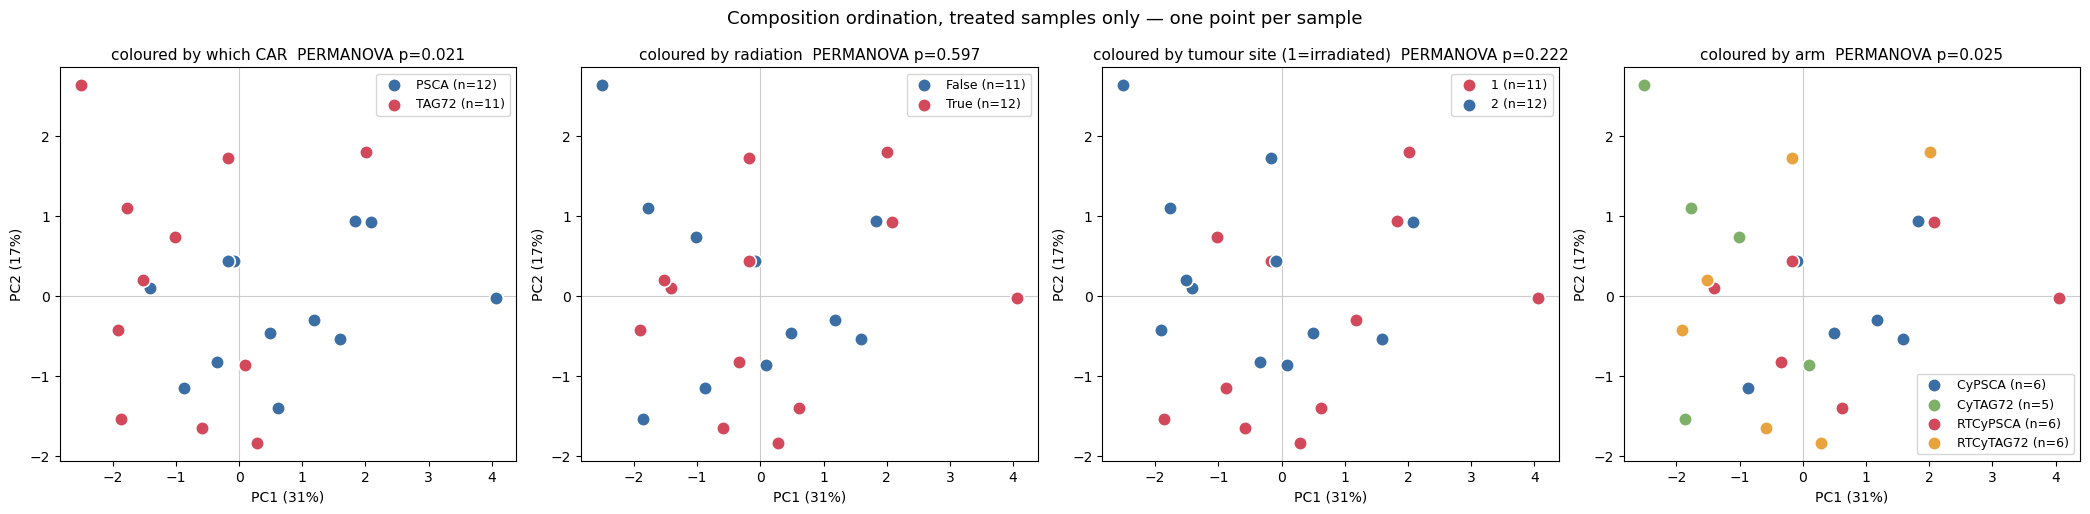

In [5]:
Cm = CLR.loc[TREATED]; mm = meta.loc[TREATED]
Z = Cm.values - Cm.values.mean(0)
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
ev = 100*S**2/(S**2).sum()
pcs = pd.DataFrame(U[:, :4]*S[:4], index=Cm.index, columns=[f"PC{i+1}" for i in range(4)]).join(mm)
load = pd.DataFrame(Vt[:4].T, index=Cm.columns, columns=[f"PC{i+1}" for i in range(4)])
pcs.to_csv(OUT/"composition_pca_scores.csv"); load.to_csv(OUT/"composition_pca_loadings.csv")
print(f"variance explained: " + "  ".join(f"PC{i+1} {ev[i]:.1f}%" for i in range(4)))
print("\nPC1 loadings (what separates left from right):")
print(pd.concat([load.PC1.nsmallest(4), load.PC1.nlargest(4)]).round(3).to_string())
print("\nPC2 loadings:")
print(pd.concat([load.PC2.nsmallest(4), load.PC2.nlargest(4)]).round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(21, 5.2))
schemes = [("cart", {"PSCA": "#3b6ea5", "TAG72": "#d1495b"}, "which CAR"),
           ("RT",   {True: "#d1495b", False: "#3b6ea5"},     "radiation"),
           ("site", {1: "#d1495b", 2: "#3b6ea5"},            "tumour site (1=irradiated)"),
           ("arm",  COL,                                      "arm")]
for ax, (fac, cmap, title) in zip(axes, schemes):
    for lev, sub in pcs.groupby(fac):
        ax.scatter(sub.PC1, sub.PC2, s=95, color=cmap.get(lev, "#999"), edgecolor="white",
                   lw=1.2, label=f"{lev} (n={len(sub)})", zorder=3)
    ax.axhline(0, color="#ccc", lw=.8); ax.axvline(0, color="#ccc", lw=.8)
    ax.set_xlabel(f"PC1 ({ev[0]:.0f}%)"); ax.set_ylabel(f"PC2 ({ev[1]:.0f}%)")
    pr = [r for r in perm_rows if r["scope"].startswith("treated") and r["factor"] == fac]
    sub_t = f"  PERMANOVA p={pr[0]['p']:.3f}" if pr else ""
    ax.set_title(f"coloured by {title}{sub_t}", fontsize=11)
    ax.legend(fontsize=9)
fig.suptitle("Composition ordination, treated samples only — one point per sample", fontsize=13)
fig.tight_layout(); fig.savefig(FIG/"02b_pca_ordination.png", dpi=250, bbox_inches="tight")
plt.show()

## 4. The interaction: does radiation do *different* things in the two CAR backgrounds?

This matters more than it looks. `01`'s decisive test required the RT effect to point the same
way in both backgrounds — that is the right rule **only if the effect is background-independent**.
The `cart x RT` term in §2 says it may not be. Here it is directly: the RT effect in PSCA on one
axis, the RT effect in TAG72 on the other.

* points on the **diagonal** = RT does the same thing in both -> `01`'s rule is valid
* points **off-axis / anti-diagonal** = RT does opposite things -> `01`'s null was a real
  interaction being averaged into nothing, and each background has to be read separately

A correlation over ~7 usable cell types is fragile, and an anti-correlation has a boring
explanation available to it — **regression to the mean**. If the two backgrounds start at
different baselines and RT nudges every population toward a common middle, the two RT-effect
vectors are anti-correlated with no interaction at all. §4b runs that control and three others
before anything is concluded. **The variance decomposition in §2 is the more robust route to the
same question**, because its interaction term is fitted per cell type from all 23 samples rather
than read off a scatter of 7 points.

RT effect (CLR delta, RT minus matched non-RT), per CAR background and site
                   PSCA_1  PSCA_2  TAG72_1  TAG72_2  PSCA_both  TAG72_both  median_cells
ct                                                                                      
Intermediate_Mac    0.812   0.222   -0.070   -0.164      0.517      -0.117         358.0
M2_like_Mac         0.573   0.325   -0.214   -0.257      0.449      -0.235         704.0
M1_like_Mac         0.773  -0.042    0.028   -0.128      0.366      -0.050         479.0
NK                  0.265   0.354   -0.198   -0.015      0.310      -0.107          32.0
pDC                -0.178   0.768   -0.366   -0.275      0.295      -0.320           7.0
Classical_Mono      0.354   0.142   -0.069   -0.311      0.248      -0.190        1042.0
Cancer_cell         0.445  -0.008   -0.357   -0.627      0.218      -0.492         175.0
cDC                 0.447  -0.122    0.182    0.002      0.163       0.092          45.0
CD4_T               0.140  -0.024 

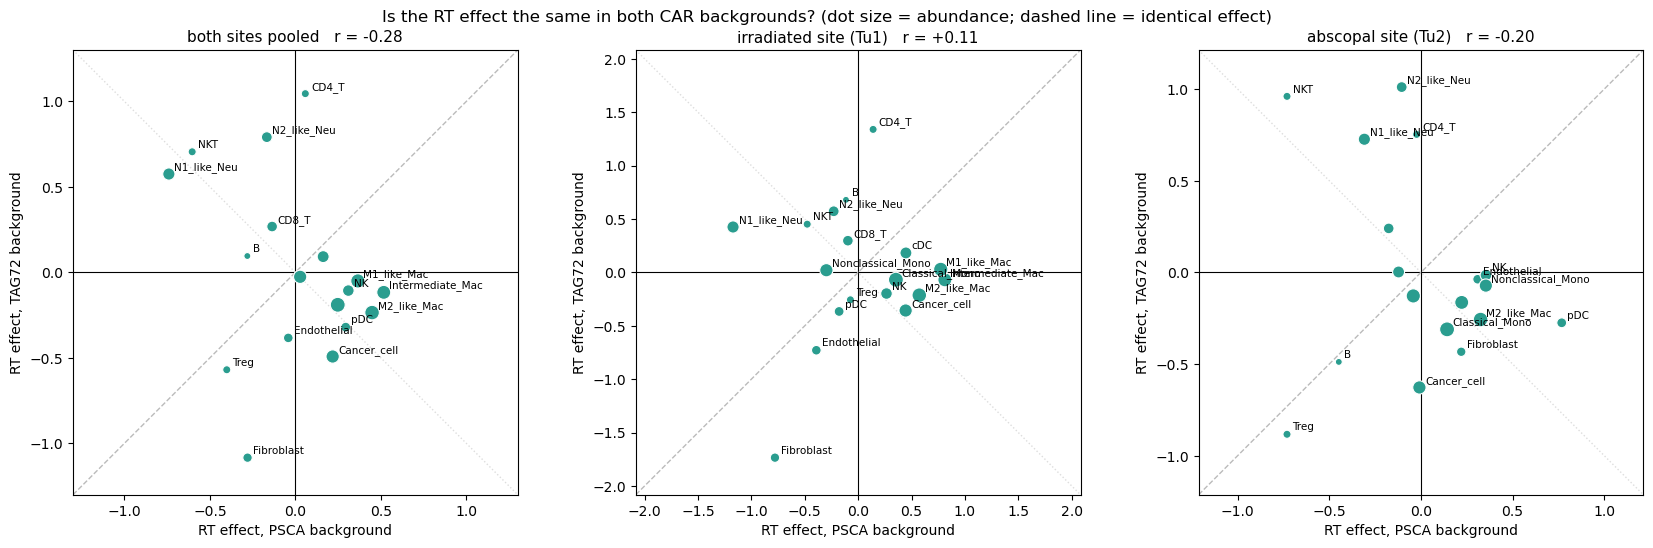

In [6]:
def rt_effect(cart, site=None):
    m = meta.cart.eq(cart) & (meta.site.eq(site) if site else True)
    a = CLR.loc[meta.index[m & meta.RT], CTS].mean()
    b = CLR.loc[meta.index[m & ~meta.RT], CTS].mean()
    return a - b

E = pd.DataFrame({f"{c}_{s}": rt_effect(c, s) for c in ["PSCA", "TAG72"] for s in [1, 2]})
E["PSCA_both"]  = E[["PSCA_1", "PSCA_2"]].mean(1)
E["TAG72_both"] = E[["TAG72_1", "TAG72_2"]].mean(1)
E["median_cells"] = cnt.median(0)
E.to_csv(OUT/"rt_effect_by_background.csv")
print("RT effect (CLR delta, RT minus matched non-RT), per CAR background and site")
print(E.round(3).sort_values("PSCA_both", ascending=False).to_string())

r_all = stats.pearsonr(E.PSCA_both, E.TAG72_both)
big = E[E.median_cells >= 50]
r_big = stats.pearsonr(big.PSCA_both, big.TAG72_both)
print(f"\ncorrelation of the two backgrounds' RT effects: all {len(E)} types r={r_all[0]:+.3f};"
      f"  the {len(big)} types with >=50 cells/sample r={r_big[0]:+.3f}")
print("  r near 0 or negative = RT is doing different things in the two backgrounds,")
print("  which is exactly what the cart x RT variance term in section 2 reported.")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, (xc, yc, ttl) in zip(axes, [("PSCA_both","TAG72_both","both sites pooled"),
                                    ("PSCA_1","TAG72_1","irradiated site (Tu1)"),
                                    ("PSCA_2","TAG72_2","abscopal site (Tu2)")]):
    lim = np.abs(E[[xc, yc]].values).max()*1.2
    ax.axhline(0, color="k", lw=.8); ax.axvline(0, color="k", lw=.8)
    ax.plot([-lim, lim], [-lim, lim], ls="--", color="#bbb", lw=1)
    ax.plot([-lim, lim], [lim, -lim], ls=":", color="#ddd", lw=1)
    sz = 25 + 90*(np.log10(E.median_cells.clip(lower=1))/np.log10(E.median_cells.max()))
    ax.scatter(E[xc], E[yc], s=sz, c="#2a9d8f", edgecolor="white", lw=.8, zorder=3)
    for ctn, r in E.iterrows():
        if abs(r[xc]) > 0.25 or abs(r[yc]) > 0.25:
            ax.annotate(ctn, (r[xc], r[yc]), fontsize=7.5, xytext=(4, 3),
                        textcoords="offset points")
    rr = stats.pearsonr(E[xc], E[yc])[0]
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel("RT effect, PSCA background"); ax.set_ylabel("RT effect, TAG72 background")
    ax.set_title(f"{ttl}   r = {rr:+.2f}", fontsize=11)
fig.suptitle("Is the RT effect the same in both CAR backgrounds? "
             "(dot size = abundance; dashed line = identical effect)", fontsize=12)
fig.tight_layout(); fig.savefig(FIG/"02b_rt_interaction.png", dpi=250, bbox_inches="tight")
plt.show()

### 4b. Four controls on the anti-correlation

| control | what a failure looks like |
|---|---|
| **A — regression to the mean** | RT effect correlates with that background's own baseline. If RT just pulls high populations down and low ones up, the two vectors anti-correlate for free |
| **B — baseline gap** | the RT effects track the PSCA-minus-TAG72 baseline difference, in opposite directions |
| **C — partial correlation** | the anti-correlation does not survive removing each background's baseline |
| **D — permutation** | shuffle RT labels within each background. With ~7 points the null is very wide, so this sets what `r` is worth |

7 cell types with >=50 cells in the median sample: ['Cancer_cell', 'Classical_Mono', 'Intermediate_Mac', 'M1_like_Mac', 'M2_like_Mac', 'N1_like_Neu', 'Nonclassical_Mono']
observed r(RT effect PSCA, RT effect TAG72) = -0.811

CONTROL A — regression to the mean
  r(baseline in PSCA, RT effect in PSCA) = +0.743 (p=0.056)
  r(baseline in TAG72, RT effect in TAG72) = -0.654 (p=0.111)   <- RT pulls this background toward the middle

CONTROL B — does the baseline gap between backgrounds drive it?
  r(PSCA-minus-TAG72 baseline, RT effect in PSCA) = -0.656 (p=0.109)
  r(PSCA-minus-TAG72 baseline, RT effect in TAG72) = +0.599 (p=0.155)
  opposite signs here = the two arms are converging, which mimics an interaction

CONTROL C — partial correlation, each background's baseline removed
  partial r = -0.624 (p=0.134)

CONTROL D — permutation null, RT labels shuffled within each background
  observed -0.811   null mean +0.005, sd 0.527
  p(null <= observed) = 0.0510
  the null sd is 0.53 on only 7 po

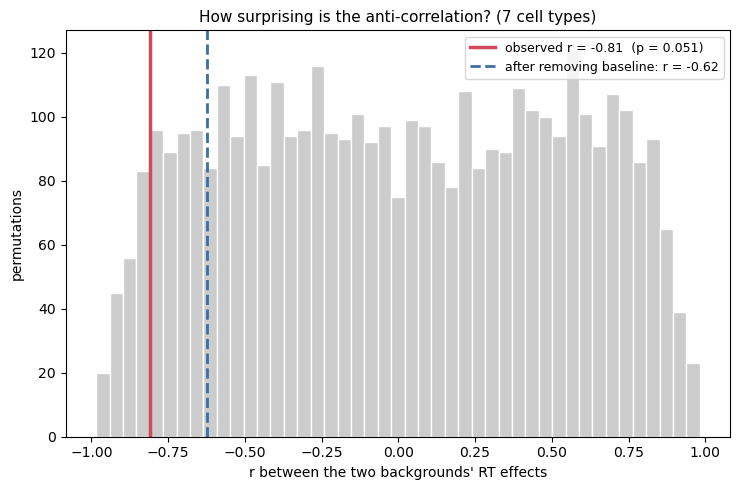

In [7]:
def bg_baseline(c):
    m = meta.cart.eq(c) & ~meta.RT
    return CLR.loc[meta.index[m], CTS].mean()

B = pd.DataFrame({"rt_PSCA": rt_effect("PSCA"), "rt_TAG72": rt_effect("TAG72"),
                  "base_PSCA": bg_baseline("PSCA"), "base_TAG72": bg_baseline("TAG72"),
                  "median_cells": cnt.median(0)})
bg = B[B.median_cells >= 50]
obs_r = stats.pearsonr(bg.rt_PSCA, bg.rt_TAG72)[0]
print(f"{len(bg)} cell types with >=50 cells in the median sample: {list(bg.index)}")
print(f"observed r(RT effect PSCA, RT effect TAG72) = {obs_r:+.3f}\n")

print("CONTROL A — regression to the mean")
ctrl_a = {}
for c in ["PSCA", "TAG72"]:
    r_, p_ = stats.pearsonr(bg[f"base_{c}"], bg[f"rt_{c}"]); ctrl_a[c] = r_
    print(f"  r(baseline in {c}, RT effect in {c}) = {r_:+.3f} (p={p_:.3f})"
          + ("   <- RT pulls this background toward the middle" if r_ < -0.5 else ""))

print("\nCONTROL B — does the baseline gap between backgrounds drive it?")
gap = bg.base_PSCA - bg.base_TAG72
for c in ["PSCA", "TAG72"]:
    r_, p_ = stats.pearsonr(gap, bg[f"rt_{c}"])
    print(f"  r(PSCA-minus-TAG72 baseline, RT effect in {c}) = {r_:+.3f} (p={p_:.3f})")
print("  opposite signs here = the two arms are converging, which mimics an interaction")

print("\nCONTROL C — partial correlation, each background's baseline removed")
def _resid(y, X):
    X = np.column_stack([np.ones(len(y))] + [np.asarray(v) for v in X])
    return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
ra = _resid(bg.rt_PSCA.values, [bg.base_PSCA.values])
rb = _resid(bg.rt_TAG72.values, [bg.base_TAG72.values])
pr, pp = stats.pearsonr(ra, rb)
print(f"  partial r = {pr:+.3f} (p={pp:.3f})")

print("\nCONTROL D — permutation null, RT labels shuffled within each background")
rg2 = np.random.default_rng(SEED)
null = []
for _ in range(4000):
    v = []
    for c in ["PSCA", "TAG72"]:
        idx = meta.index[meta.cart.eq(c)]
        lab = meta.loc[idx, "RT"].values.copy(); rg2.shuffle(lab)
        v.append(CLR.loc[idx[lab], bg.index].mean() - CLR.loc[idx[~lab], bg.index].mean())
    null.append(stats.pearsonr(v[0], v[1])[0])
null = np.array(null)
p_perm = float(np.mean(null <= obs_r))
print(f"  observed {obs_r:+.3f}   null mean {null.mean():+.3f}, sd {null.std():.3f}")
print(f"  p(null <= observed) = {p_perm:.4f}")
print(f"  the null sd is {null.std():.2f} on only {len(bg)} points, so |r| has to exceed ~{2*null.std():.1f}")
print(f"  to mean anything at all. {abs(obs_r):.2f} clears that, but not by much.")

INTERACTION_VERDICT = (
    "ESTABLISHED" if (p_perm < 0.01 and pp < 0.05 and min(ctrl_a.values()) > -0.5) else
    "SUGGESTIVE, NOT ESTABLISHED" if p_perm < 0.10 else "NOT SUPPORTED")
print(f"\nVERDICT on the interaction from this scatter: {INTERACTION_VERDICT}")
print("  The defensible statement is the weaker one: do NOT assume the RT effect points the")
print("  same way in both CAR backgrounds. Section 2's per-cell-type interaction term is the")
print("  evidence to lean on, not this correlation.")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.hist(null, bins=45, color="#cccccc", edgecolor="white")
ax.axvline(obs_r, color="#d1495b", lw=2.5, label=f"observed r = {obs_r:+.2f}  (p = {p_perm:.3f})")
ax.axvline(pr, color="#3b6ea5", lw=2, ls="--",
           label=f"after removing baseline: r = {pr:+.2f}")
ax.set_xlabel("r between the two backgrounds' RT effects"); ax.set_ylabel("permutations")
ax.set_title(f"How surprising is the anti-correlation? ({len(bg)} cell types)", fontsize=11)
ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(FIG/"02b_interaction_controls.png", dpi=250, bbox_inches="tight")
plt.show()

## 5. Every group against every group, per cell type

A 10 x 10 grid for each cell type: colour is the log2 fold change of the row group over the
column group, `*` marks p<0.05 and `+` marks p<0.10 (unadjusted, on log percentage). Cell types
are ordered by how much total variation they carry, and the `NoTx` rows/columns are boxed off
because they are the treatment effect, not an RT effect.

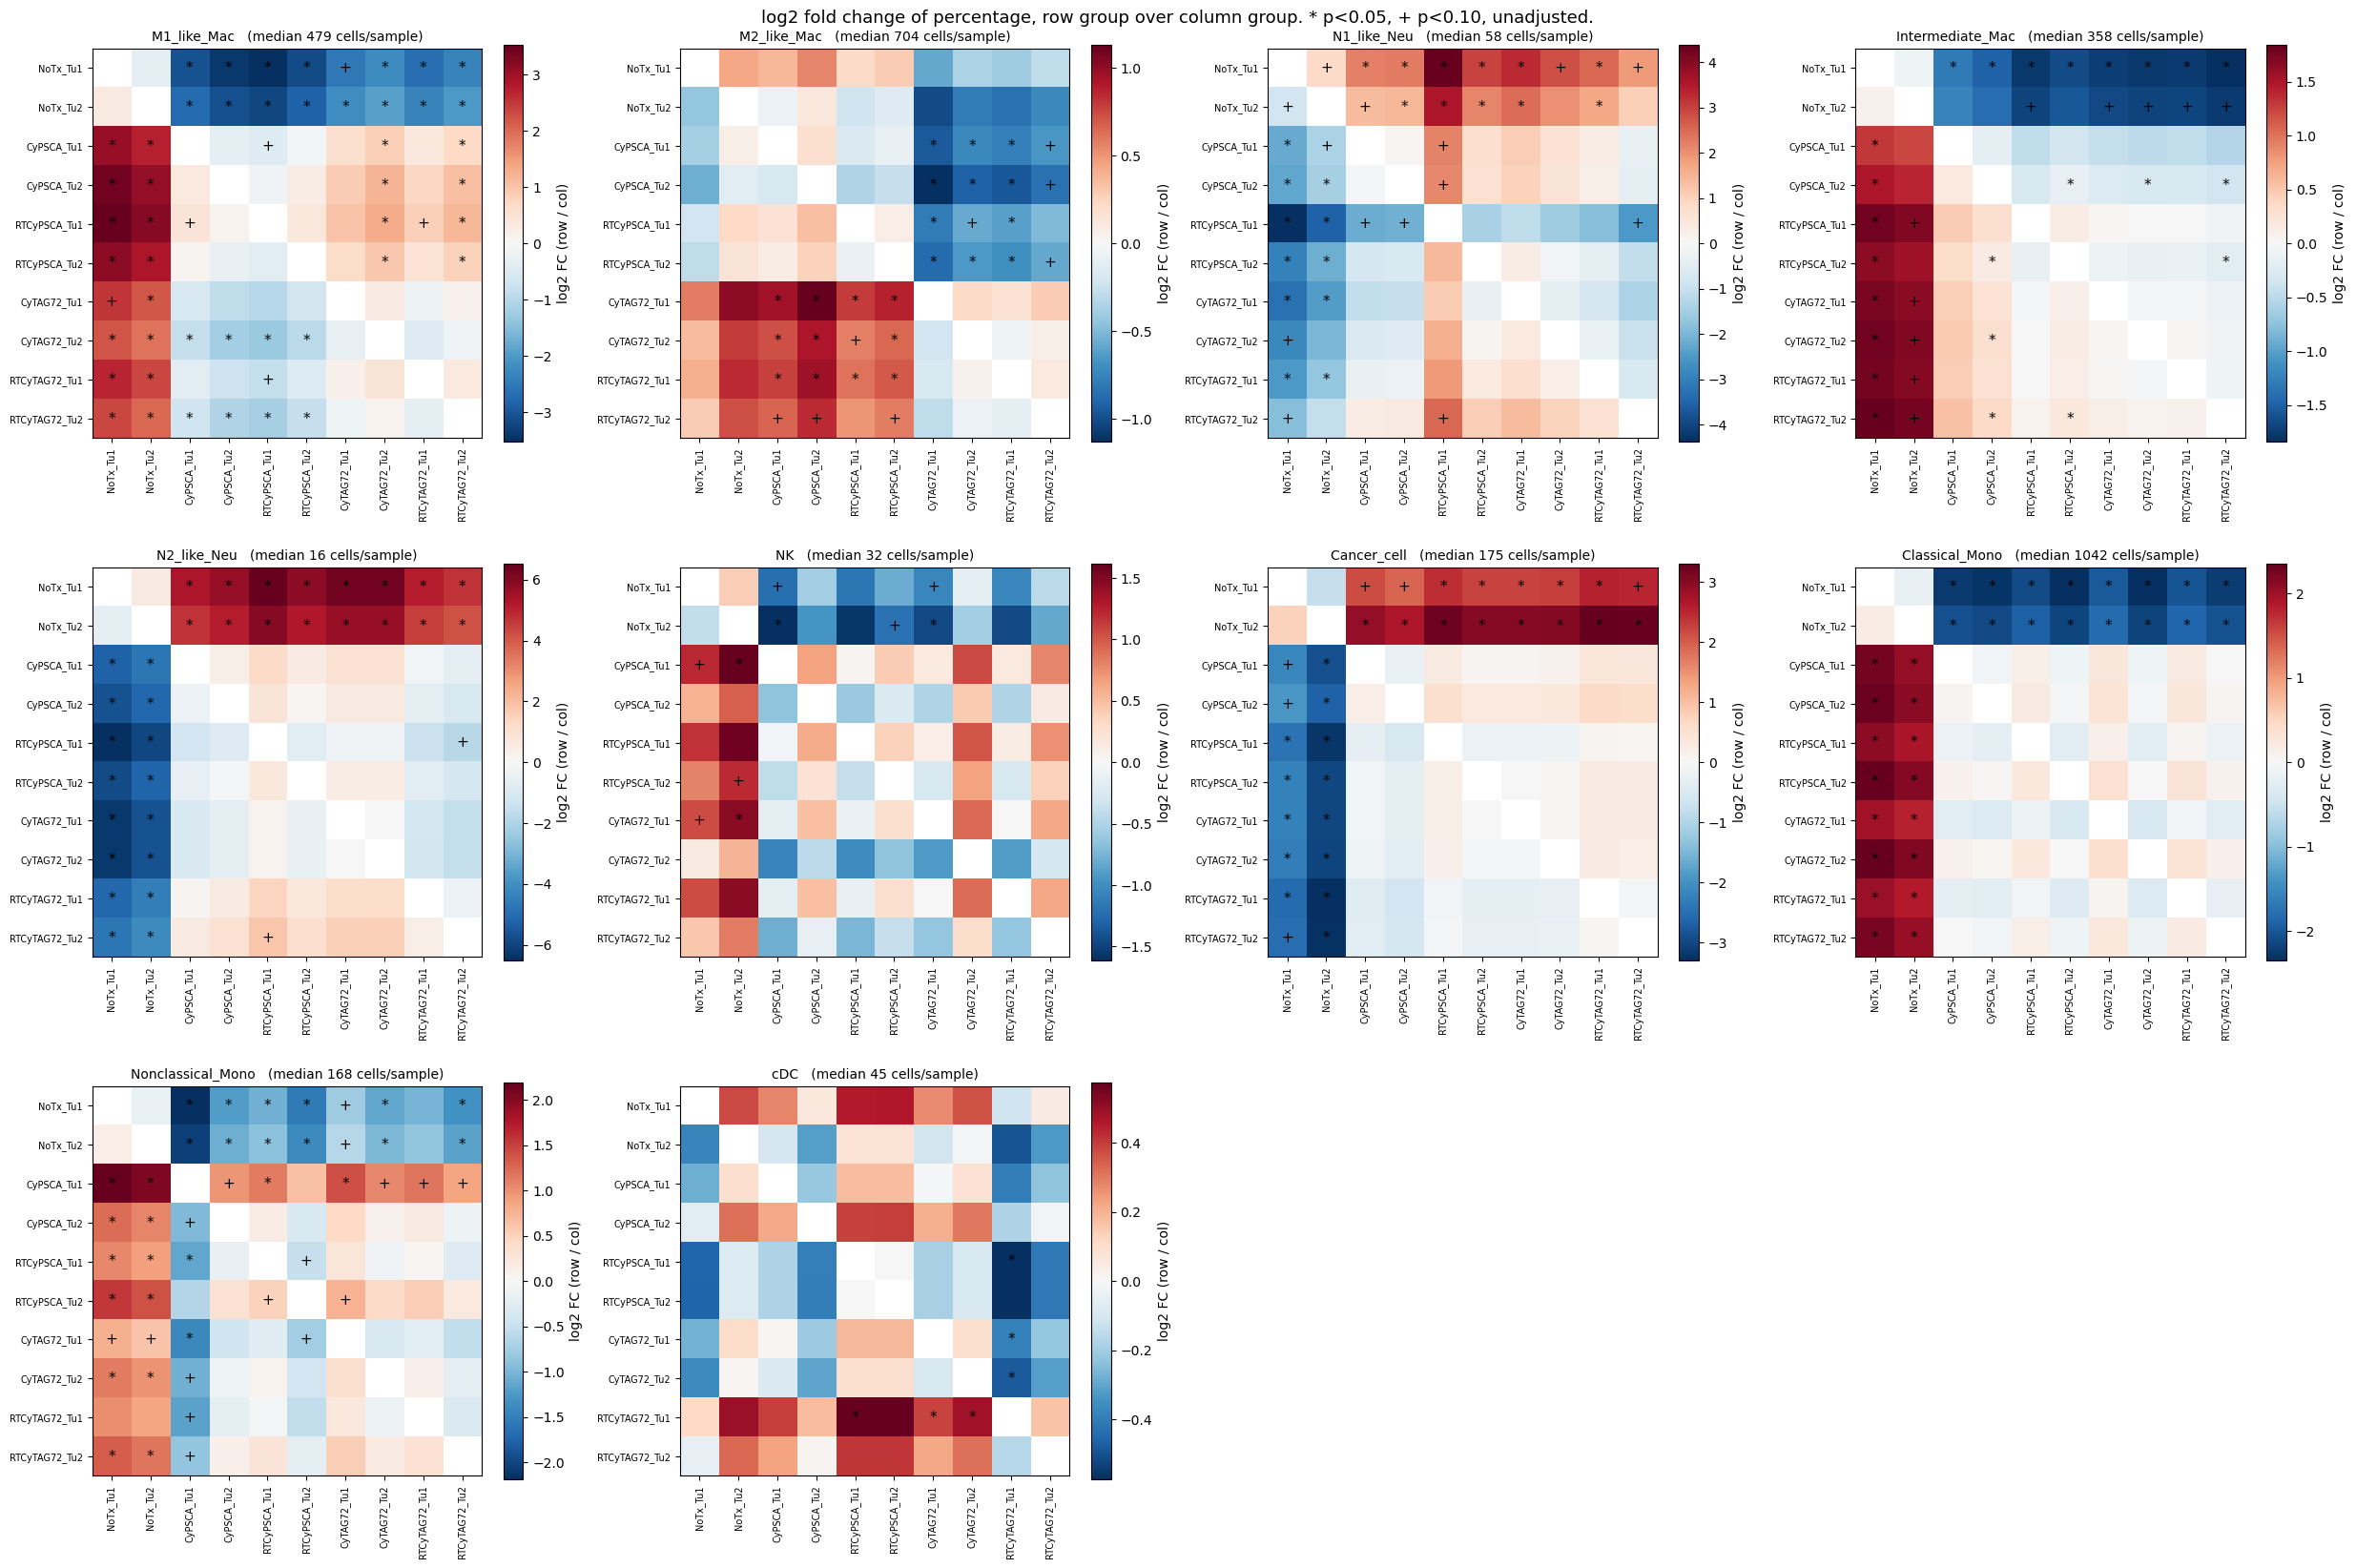

In [8]:
GRPS = [f"{a}_Tu{s}" for a in ARM_ORDER for s in [1, 2]]
GRPS = [g for g in GRPS if g in set(meta.grp)]
lp = np.log(prop + 1e-6)

def grid_for(ct):
    fc = pd.DataFrame(np.nan, index=GRPS, columns=GRPS)
    pv = pd.DataFrame(np.nan, index=GRPS, columns=GRPS)
    for a, b in itertools.permutations(GRPS, 2):
        ia, ib = meta.index[meta.grp == a], meta.index[meta.grp == b]
        pa, pb = prop.loc[ia, ct], prop.loc[ib, ct]
        fc.loc[a, b] = np.log2((pa.mean()+1e-9)/(pb.mean()+1e-9))
        pv.loc[a, b] = stats.ttest_ind(lp.loc[ia, ct], lp.loc[ib, ct], equal_var=False)[1]
    return fc, pv

order = V.index[V[["cart","RT","site","cart x RT"]].sum(1).argsort()[::-1]]
show = [c for c in order if cnt[c].median() >= 15][:12]
nr = int(np.ceil(len(show)/4))
fig, axes = plt.subplots(nr, 4, figsize=(6.2*4, 5.6*nr))
for ax, ct in zip(np.ravel(axes), show):
    fc, pv = grid_for(ct)
    v = np.nanmax(np.abs(fc.values))
    im = ax.imshow(fc.values, cmap="RdBu_r", norm=TwoSlopeNorm(0, -v, v))
    for i in range(len(GRPS)):
        for j in range(len(GRPS)):
            if i == j: continue
            mk = "*" if pv.iloc[i, j] < 0.05 else ("+" if pv.iloc[i, j] < 0.10 else "")
            if mk: ax.text(j, i, mk, ha="center", va="center", fontsize=11, color="k")
    ax.set_xticks(range(len(GRPS))); ax.set_xticklabels(GRPS, rotation=90, fontsize=7)
    ax.set_yticks(range(len(GRPS))); ax.set_yticklabels(GRPS, fontsize=7)
    ax.set_title(f"{ct}   (median {int(cnt[ct].median())} cells/sample)", fontsize=10)
    plt.colorbar(im, ax=ax, fraction=.046, label="log2 FC (row / col)")
for ax in np.ravel(axes)[len(show):]: ax.axis("off")
fig.suptitle("log2 fold change of percentage, row group over column group. "
             "* p<0.05, + p<0.10, unadjusted.", fontsize=13)
fig.tight_layout(); fig.savefig(FIG/"02b_pairwise_grids.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Volcano plots for the eight comparisons that matter

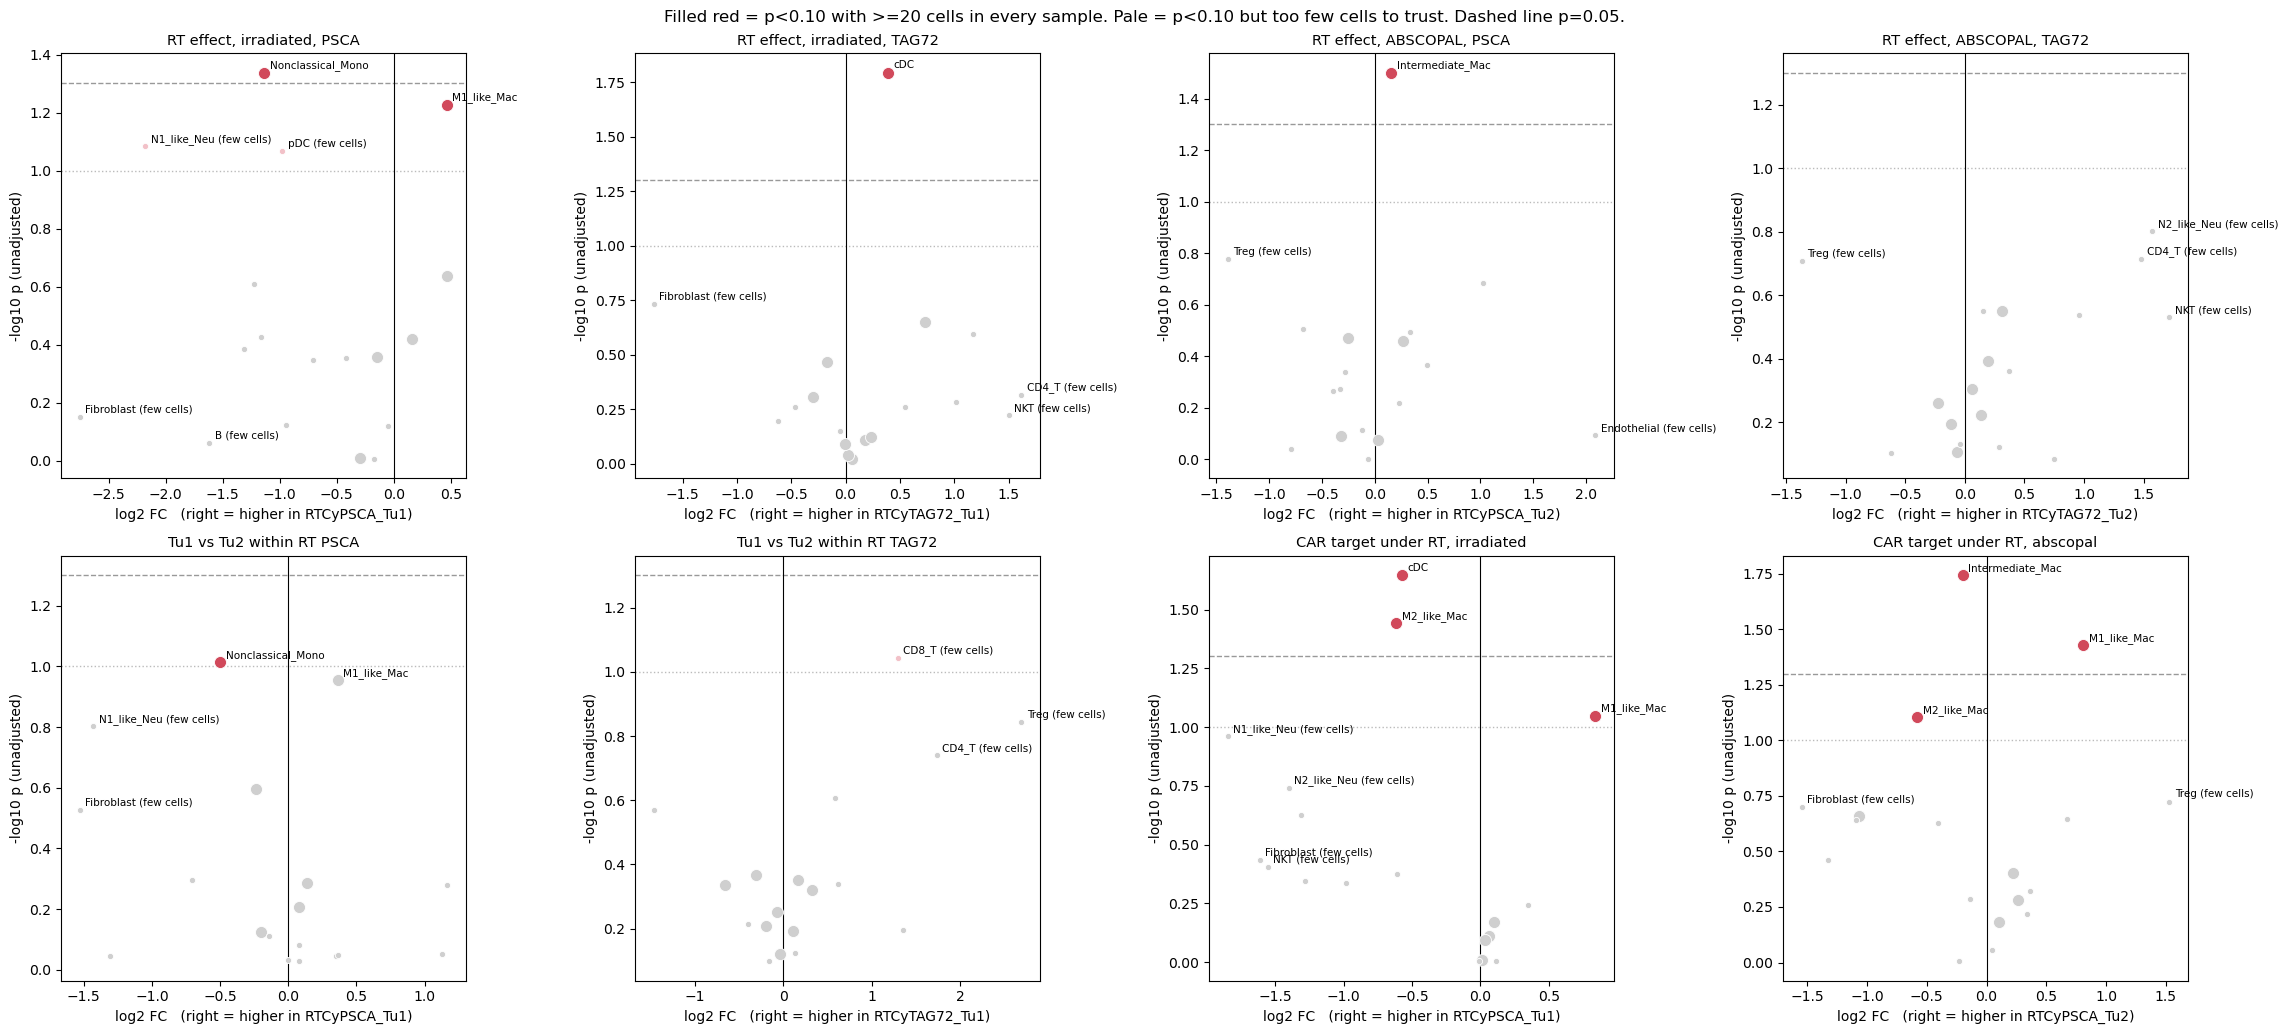

everything reaching p<0.10 with >=20 cells in every sample:
            A             B         cell_type  log2FC     p  min_cells  separated
RTCyTAG72_Tu1   CyTAG72_Tu1               cDC   0.387 0.016         56       True
 RTCyPSCA_Tu2 RTCyTAG72_Tu2  Intermediate_Mac  -0.200 0.018        203       True
 RTCyPSCA_Tu1 RTCyTAG72_Tu1               cDC  -0.573 0.023         33       True
 RTCyPSCA_Tu2    CyPSCA_Tu2  Intermediate_Mac   0.155 0.032         44       True
 RTCyPSCA_Tu1 RTCyTAG72_Tu1       M2_like_Mac  -0.614 0.036        580       True
 RTCyPSCA_Tu2 RTCyTAG72_Tu2       M1_like_Mac   0.808 0.037        265       True
 RTCyPSCA_Tu1    CyPSCA_Tu1 Nonclassical_Mono  -1.136 0.046        166       True
 RTCyPSCA_Tu1    CyPSCA_Tu1       M1_like_Mac   0.462 0.059        343       True
 RTCyPSCA_Tu2 RTCyTAG72_Tu2       M2_like_Mac  -0.578 0.078        451       True
 RTCyPSCA_Tu1 RTCyTAG72_Tu1       M1_like_Mac   0.839 0.089        499       True
 RTCyPSCA_Tu1  RTCyPSCA_Tu2 Nonclassic

In [9]:
FOCUS = [("RTCyPSCA_Tu1","CyPSCA_Tu1","RT effect, irradiated, PSCA"),
         ("RTCyTAG72_Tu1","CyTAG72_Tu1","RT effect, irradiated, TAG72"),
         ("RTCyPSCA_Tu2","CyPSCA_Tu2","RT effect, ABSCOPAL, PSCA"),
         ("RTCyTAG72_Tu2","CyTAG72_Tu2","RT effect, ABSCOPAL, TAG72"),
         ("RTCyPSCA_Tu1","RTCyPSCA_Tu2","Tu1 vs Tu2 within RT PSCA"),
         ("RTCyTAG72_Tu1","RTCyTAG72_Tu2","Tu1 vs Tu2 within RT TAG72"),
         ("RTCyPSCA_Tu1","RTCyTAG72_Tu1","CAR target under RT, irradiated"),
         ("RTCyPSCA_Tu2","RTCyTAG72_Tu2","CAR target under RT, abscopal")]

fig, axes = plt.subplots(2, 4, figsize=(23, 10.5))
vol = []
for ax, (a, b, ttl) in zip(np.ravel(axes), FOCUS):
    ia, ib = meta.index[meta.grp == a], meta.index[meta.grp == b]
    for ct in CTS:
        pa, pb = prop.loc[ia, ct], prop.loc[ib, ct]
        l2 = np.log2((pa.mean()+1e-9)/(pb.mean()+1e-9))
        pp = stats.ttest_ind(lp.loc[ia, ct], lp.loc[ib, ct], equal_var=False)[1]
        mc = int(min(cnt.loc[ia, ct].min(), cnt.loc[ib, ct].min()))
        sep = bool(pa.min() > pb.max() or pa.max() < pb.min())
        vol.append(dict(A=a, B=b, cell_type=ct, log2FC=l2, p=pp, min_cells=mc, separated=sep))
        colr = "#d1495b" if (pp < 0.10 and mc >= 20) else ("#f2c1c8" if pp < 0.10 else "#cfcfcf")
        ax.scatter(l2, -np.log10(max(pp, 1e-12)), s=20+55*(mc >= 20), color=colr,
                   edgecolor="white", lw=.6, zorder=3)
        if pp < 0.20 or abs(l2) > 1.5:
            ax.annotate(ct + ("" if mc >= 20 else " (few cells)"), (l2, -np.log10(max(pp, 1e-12))),
                        fontsize=7.5, xytext=(4, 3), textcoords="offset points")
    ax.axhline(-np.log10(0.05), ls="--", color="#999", lw=1)
    ax.axhline(-np.log10(0.10), ls=":", color="#bbb", lw=1)
    ax.axvline(0, color="k", lw=.8)
    ax.set_xlabel(f"log2 FC   (right = higher in {a})"); ax.set_ylabel("-log10 p (unadjusted)")
    ax.set_title(ttl, fontsize=10.5)
Vol = pd.DataFrame(vol); Vol.to_csv(OUT/"volcano_focus_comparisons.csv", index=False)
fig.suptitle("Filled red = p<0.10 with >=20 cells in every sample. Pale = p<0.10 but too few "
             "cells to trust. Dashed line p=0.05.", fontsize=12)
fig.tight_layout(); fig.savefig(FIG/"02b_volcanoes.png", dpi=200, bbox_inches="tight")
plt.show()

print("everything reaching p<0.10 with >=20 cells in every sample:")
print(Vol[(Vol.p < 0.10) & (Vol.min_cells >= 20)].sort_values("p")
        .round(3).to_string(index=False))

## 7. Every animal, every cell type

Averages over three mice hide whether all three moved. One line per mouse, left point = `Tu1`
(irradiated), right point = `Tu2` (abscopal). A beam effect needs the red lines to tilt where
the blue ones do not.

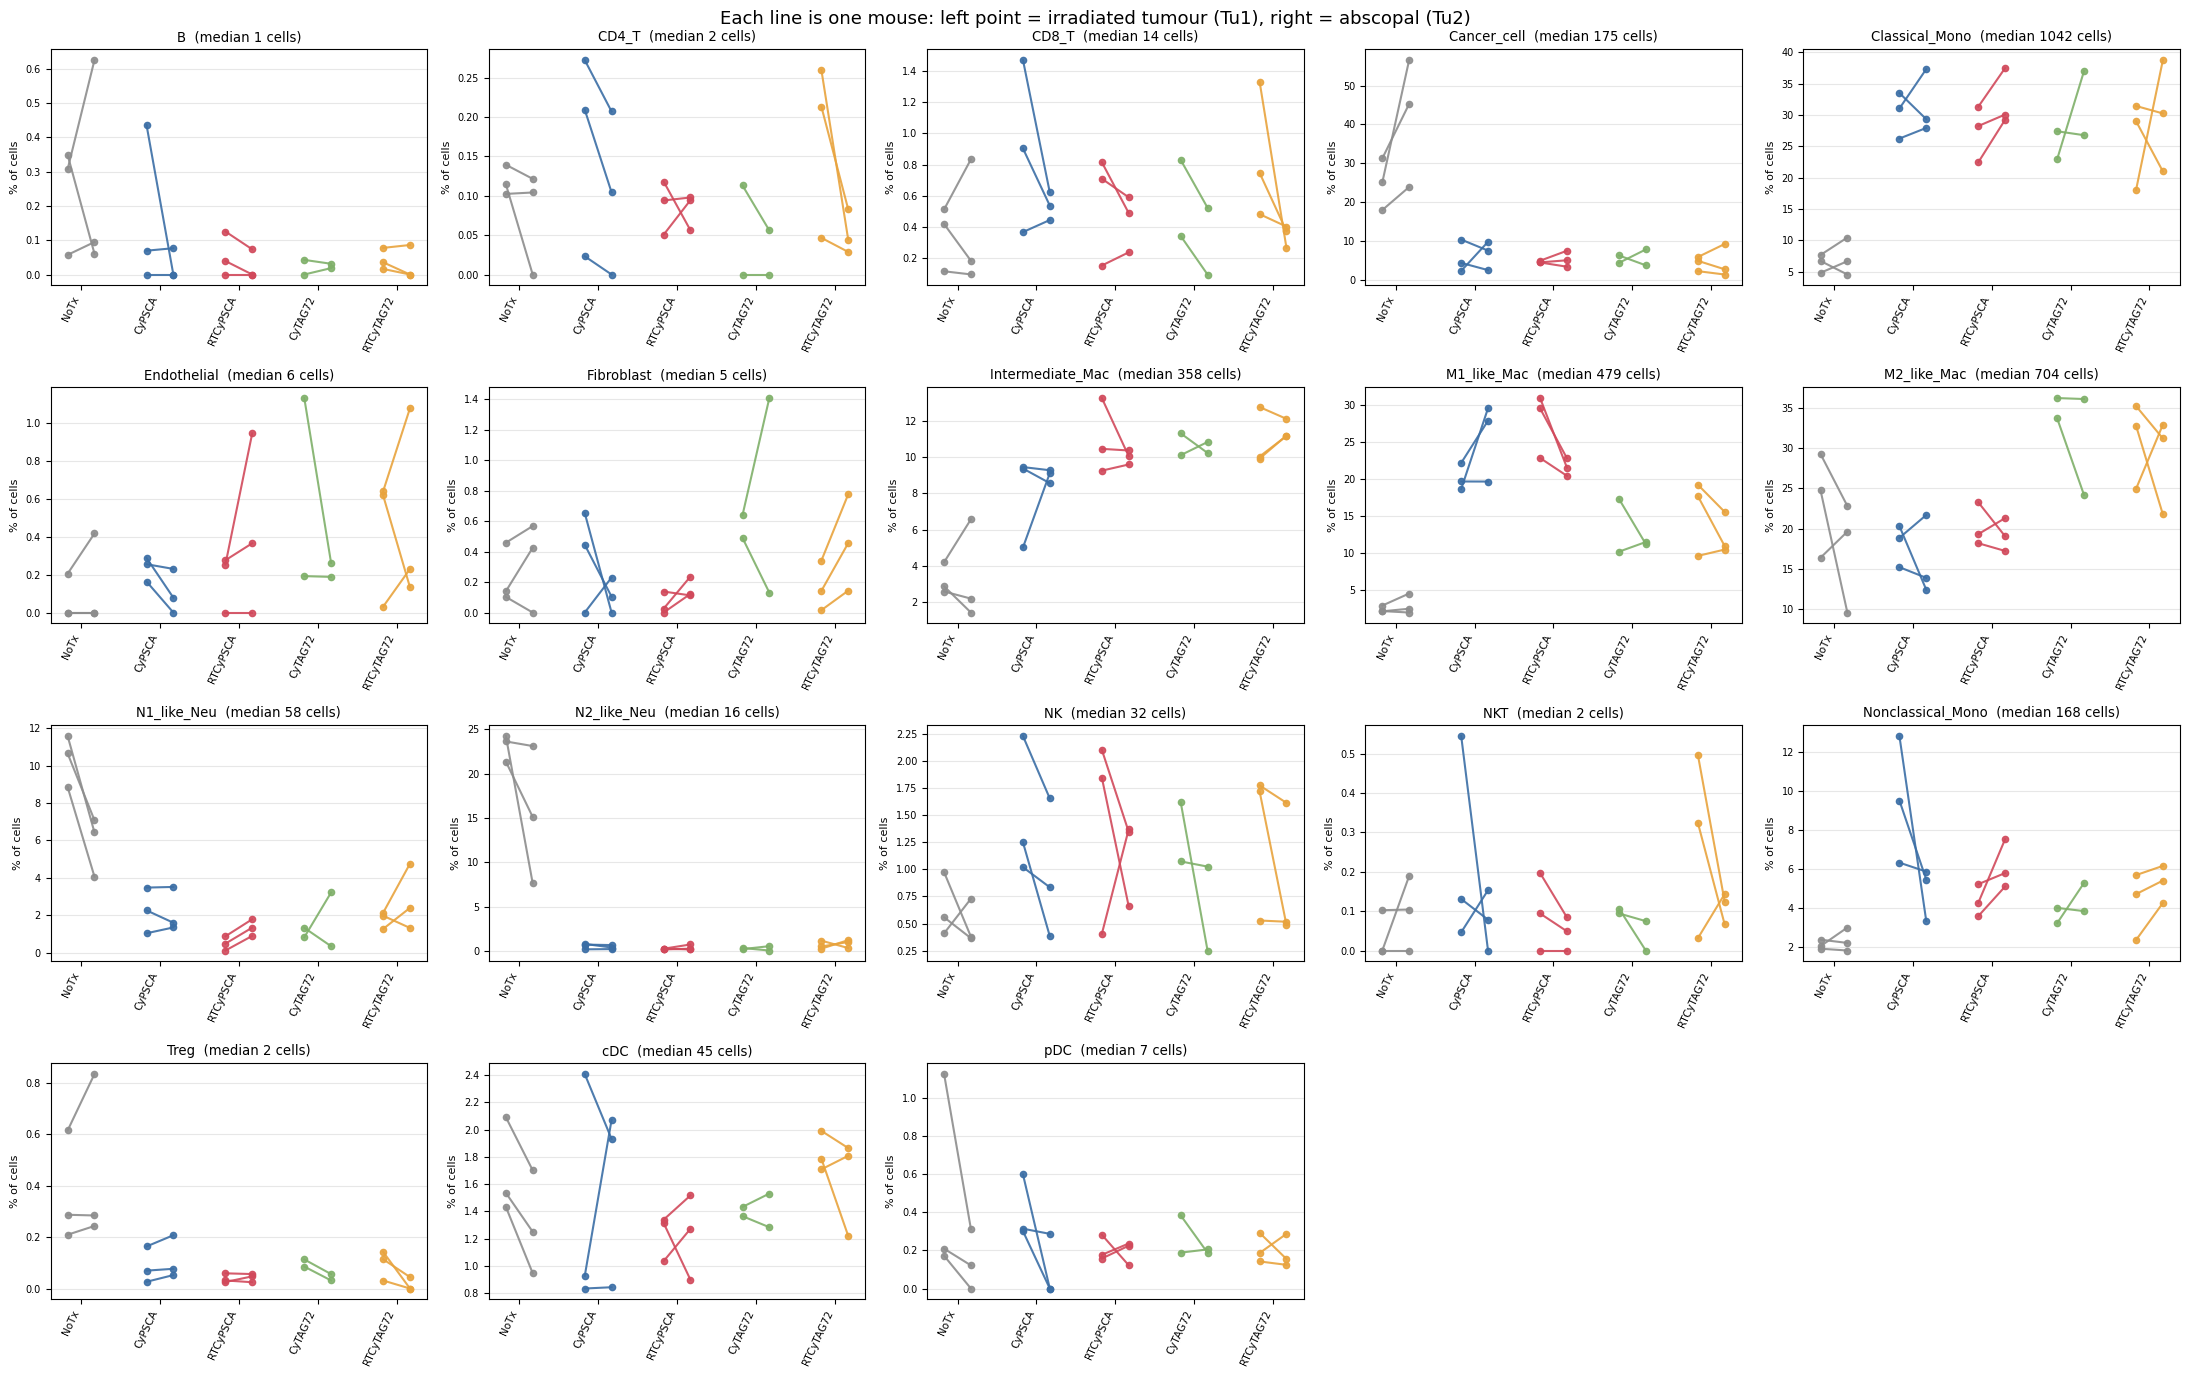

In [10]:
pc = (prop*100).join(meta)
nr = int(np.ceil(len(CTS)/5))
fig, axes = plt.subplots(nr, 5, figsize=(4.4*5, 3.5*nr))
for ax, ct in zip(np.ravel(axes), CTS):
    for i, arm in enumerate(ARM_ORDER):
        d = pc[pc.arm == arm]
        for mse, g in d.groupby("mouse"):
            if g.site.nunique() < 2: continue
            y1 = g[g.site == 1][ct].iloc[0]; y2 = g[g.site == 2][ct].iloc[0]
            ax.plot([i-0.17, i+0.17], [y1, y2], color=COL[arm], marker="o", ms=4.5, lw=1.5,
                    alpha=.9)
    ax.set_xticks(range(len(ARM_ORDER)))
    ax.set_xticklabels(ARM_ORDER, rotation=65, fontsize=7.5, ha="right")
    ax.set_title(f"{ct}  (median {int(cnt[ct].median())} cells)", fontsize=9.5)
    ax.set_ylabel("% of cells", fontsize=8); ax.grid(axis="y", alpha=.3)
    ax.tick_params(axis="y", labelsize=7)
for ax in np.ravel(axes)[len(CTS):]: ax.axis("off")
fig.suptitle("Each line is one mouse: left point = irradiated tumour (Tu1), right = abscopal (Tu2)",
             fontsize=13)
fig.tight_layout(); fig.savefig(FIG/"02b_per_mouse_all_celltypes.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. `M1_like_Mac` — the one RT lead, from every angle

`02` found 20.2% -> 27.8% at the irradiated site in the PSCA background, fully separated. This
section tries to break it: every animal, both sites, both backgrounds, the ratio to `M2_like_Mac`,
and whether it tracks anything else in the sample.

--- M1_like_Mac, every sample ---
                 M1_like_Mac  M2_like_Mac        arm  site         mouse  M1_over_M2  n_cells
sample                                                                                       
CyPSCA_Tu1_1           22.21        20.30     CyPSCA     1     CyPSCA_m1        0.13      849
CyPSCA_Tu1_2           19.70        18.85     CyPSCA     1     CyPSCA_m2        0.06      851
CyPSCA_Tu1_3           18.68        15.20     CyPSCA     1     CyPSCA_m3        0.30      343
CyPSCA_Tu2_1           27.92        12.40     CyPSCA     2     CyPSCA_m1        1.17     1070
CyPSCA_Tu2_2           19.69        21.69     CyPSCA     2     CyPSCA_m2       -0.14      257
CyPSCA_Tu2_3           29.61        13.87     CyPSCA     2     CyPSCA_m3        1.09      143
CyTAG72_Tu1_1          10.21        36.24    CyTAG72     1    CyTAG72_m1       -1.83      479
CyTAG72_Tu1_3          17.35        33.71    CyTAG72     1    CyTAG72_m3       -0.96      921
CyTAG72_Tu2_1          11.

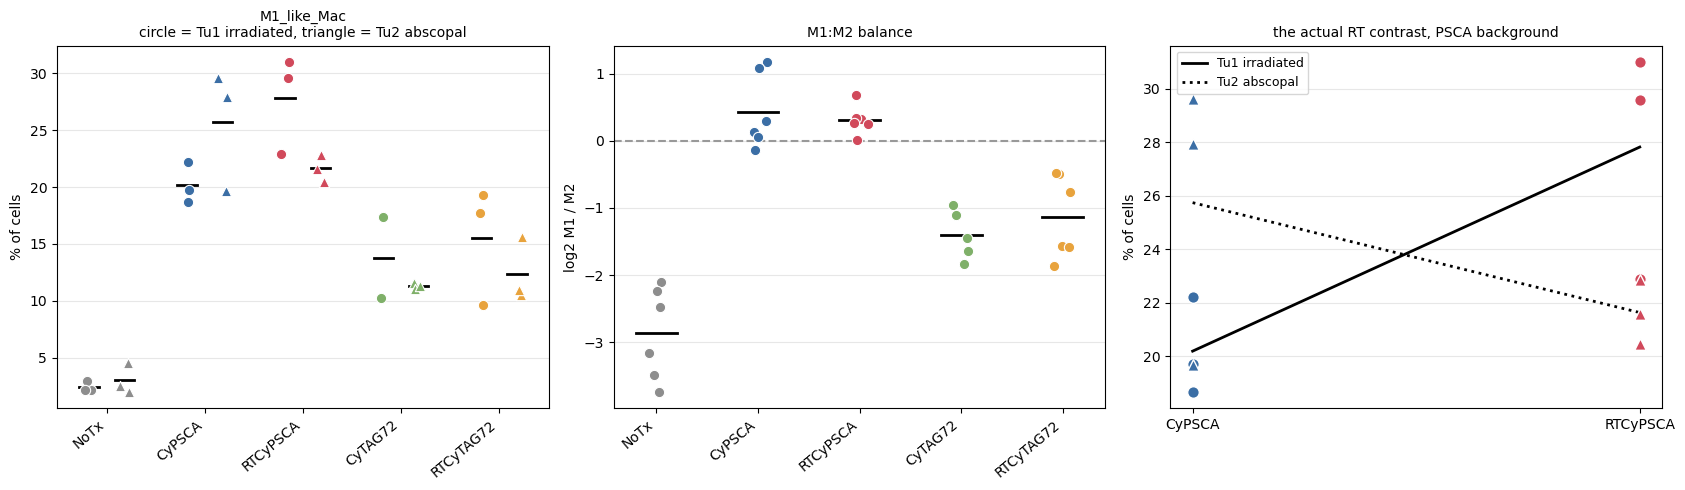

In [11]:
CT = "M1_like_Mac"
print(f"--- {CT}, every sample ---")
t = pc[[CT, "M2_like_Mac", "arm", "site", "mouse"]].copy()
t["M1_over_M2"] = np.log2((cnt[CT]+PSEUDO)/(cnt["M2_like_Mac"]+PSEUDO))
t["n_cells"] = cnt[CT]
print(t.sort_values(["arm", "site"]).round(2).to_string())

print(f"\n--- group means ---")
g = t.groupby(["arm", "site"], observed=True).agg(
        pct=(CT, "mean"), sd=(CT, "std"), n_mice=(CT, "size"),
        cells=("n_cells", "mean"), M1_over_M2=("M1_over_M2", "mean")).round(2)
print(g.to_string())

print("\n--- every comparison involving this cell type, treated vs treated ---")
rows = []
for a, b in itertools.combinations([g_ for g_ in GRPS if not g_.startswith("NoTx")], 2):
    ia, ib = meta.index[meta.grp == a], meta.index[meta.grp == b]
    pa, pb = prop.loc[ia, CT], prop.loc[ib, CT]
    rows.append(dict(A=a, B=b, pctA=100*pa.mean(), pctB=100*pb.mean(),
                     log2FC=np.log2(pa.mean()/pb.mean()),
                     p=stats.ttest_ind(lp.loc[ia, CT], lp.loc[ib, CT], equal_var=False)[1],
                     separated=bool(pa.min() > pb.max() or pa.max() < pb.min())))
print(pd.DataFrame(rows).sort_values("p").round(3).to_string(index=False))

print("\n--- does M1 abundance track anything else in the same sample? ---")
co = CLR.loc[TREATED].corrwith(CLR.loc[TREATED, CT]).drop(CT).sort_values()
print(pd.concat([co.head(4), co.tail(4)]).round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
for i, arm in enumerate(ARM_ORDER):
    for s, off in [(1, -0.18), (2, 0.18)]:
        v = pc[(pc.arm == arm) & (pc.site == s)][CT]
        if not len(v): continue
        ax.scatter(np.full(len(v), i+off) + rng.uniform(-.05, .05, len(v)), v, s=55,
                   color=COL[arm], marker="o" if s == 1 else "^", edgecolor="white", lw=.8,
                   zorder=3, label=None)
        ax.plot([i+off-.1, i+off+.1], [v.mean()]*2, color="k", lw=2)
ax.set_xticks(range(len(ARM_ORDER))); ax.set_xticklabels(ARM_ORDER, rotation=40, ha="right")
ax.set_ylabel("% of cells"); ax.set_title(f"{CT}\ncircle = Tu1 irradiated, triangle = Tu2 abscopal",
                                          fontsize=10)
ax.grid(axis="y", alpha=.3)

ax = axes[1]
for i, arm in enumerate(ARM_ORDER):
    v = t[t.arm == arm]["M1_over_M2"]
    ax.scatter(np.full(len(v), i) + rng.uniform(-.1, .1, len(v)), v, s=55, color=COL[arm],
               edgecolor="white", lw=.8, zorder=3)
    ax.plot([i-.2, i+.2], [v.mean()]*2, color="k", lw=2)
ax.axhline(0, color="#999", ls="--")
ax.set_xticks(range(len(ARM_ORDER))); ax.set_xticklabels(ARM_ORDER, rotation=40, ha="right")
ax.set_ylabel("log2 M1 / M2"); ax.set_title("M1:M2 balance", fontsize=10); ax.grid(axis="y", alpha=.3)

ax = axes[2]
d = pc[pc.arm.isin(["CyPSCA", "RTCyPSCA"])]
for arm in ["CyPSCA", "RTCyPSCA"]:
    for s, mk in [(1, "o"), (2, "^")]:
        v = d[(d.arm == arm) & (d.site == s)][CT]
        ax.scatter([0 if arm == "CyPSCA" else 1]*len(v), v, s=70, marker=mk, color=COL[arm],
                   edgecolor="white", lw=1, zorder=3)
for s, ls in [(1, "-"), (2, ":")]:
    y = [d[(d.arm == a) & (d.site == s)][CT].mean() for a in ["CyPSCA", "RTCyPSCA"]]
    ax.plot([0, 1], y, color="k", ls=ls, lw=2, label=f"Tu{s} {'irradiated' if s==1 else 'abscopal'}")
ax.set_xticks([0, 1]); ax.set_xticklabels(["CyPSCA", "RTCyPSCA"])
ax.set_ylabel("% of cells"); ax.legend(fontsize=9)
ax.set_title("the actual RT contrast, PSCA background", fontsize=10); ax.grid(axis="y", alpha=.3)
fig.tight_layout(); fig.savefig(FIG/"02b_m1_deep_dive.png", dpi=250, bbox_inches="tight")
plt.show()

## 9. Which populations move together?

Correlation of CLR abundance across the 23 treated samples, hierarchically ordered. Blocks here
are the real degrees of freedom: if six cell types move as one, the 18 "independent" tests in
`02` were closer to a handful.

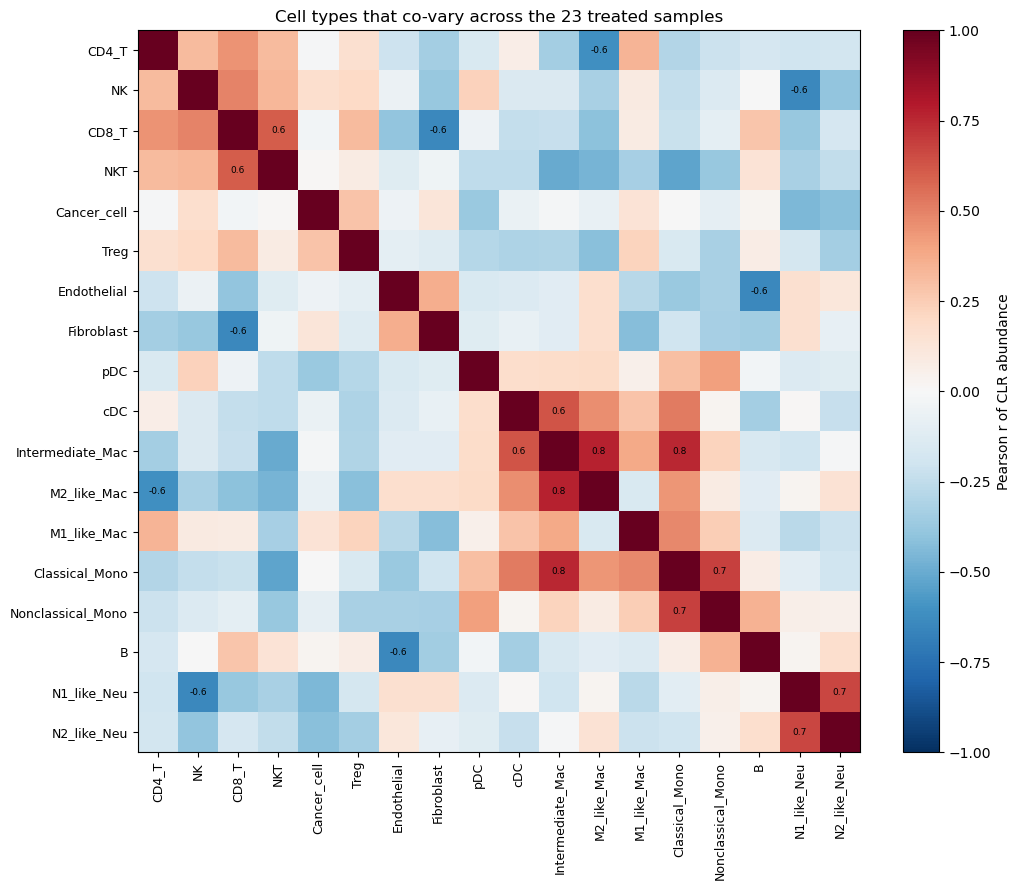

10 pairs with |r| > 0.6 out of 153:
  Intermediate_Mac   M2_like_Mac        r = +0.77
  Intermediate_Mac   Classical_Mono     r = +0.75
  Classical_Mono     Nonclassical_Mono  r = +0.69
  N1_like_Neu        N2_like_Neu        r = +0.67
  Endothelial        B                  r = -0.64
  CD8_T              Fibroblast         r = -0.64
  NK                 N1_like_Neu        r = -0.64
  cDC                Intermediate_Mac   r = +0.63
  CD4_T              M2_like_Mac        r = -0.62
  CD8_T              NKT                r = +0.60


In [12]:
Cc = CLR.loc[TREATED, CTS].corr()
Zl = linkage(squareform(1-Cc.values, checks=False), "average")
ordr = [CTS[i] for i in leaves_list(Zl)]
Cc = Cc.loc[ordr, ordr]
fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(Cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordr))); ax.set_xticklabels(ordr, rotation=90, fontsize=9)
ax.set_yticks(range(len(ordr))); ax.set_yticklabels(ordr, fontsize=9)
for i in range(len(ordr)):
    for j in range(len(ordr)):
        if i != j and abs(Cc.values[i, j]) > 0.6:
            ax.text(j, i, f"{Cc.values[i,j]:.1f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(Cc.values[i, j]) > 0.8 else "black")
plt.colorbar(im, ax=ax, fraction=.045, label="Pearson r of CLR abundance")
ax.set_title("Cell types that co-vary across the 23 treated samples", fontsize=12)
fig.tight_layout(); fig.savefig(FIG/"02b_celltype_covariation.png", dpi=250, bbox_inches="tight")
plt.show()
Cc.to_csv(OUT/"celltype_covariation.csv")

pairs = [(a, b, Cc.loc[a, b]) for a, b in itertools.combinations(ordr, 2) if abs(Cc.loc[a, b]) > .6]
print(f"{len(pairs)} pairs with |r| > 0.6 out of {len(list(itertools.combinations(CTS,2)))}:")
for a, b, r_ in sorted(pairs, key=lambda z: -abs(z[2])):
    print(f"  {a:<18s} {b:<18s} r = {r_:+.2f}")

## 10. How big is an RT effect compared with the other axes?

Every treated-vs-treated comparison, classified by what it contrasts, and the distribution of
absolute effect sizes. This is the summary answer to *"what actually separates these tumours?"*

EFFECT SIZE AND HIT RATE BY CONTRAST TYPE (>=20 cells in every sample)
                                          n  median_abs_log2FC  mean_abs_log2FC  frac_p_lt_05  frac_p_lt_10  excess_over_chance
kind                                                                                                                           
treated vs untreated (scale reference)   95              2.035            1.828         0.674         0.758               13.48
CAR TARGET (same RT status, same site)   27              0.355            0.489         0.333         0.407                6.66
mixed                                   107              0.321            0.417         0.150         0.215                3.00
tumour site (Tu1 vs Tu2, same arm)       26              0.198            0.223         0.000         0.038                0.00
RADIATION (same CAR, same site)          27              0.197            0.256         0.111         0.148                2.22


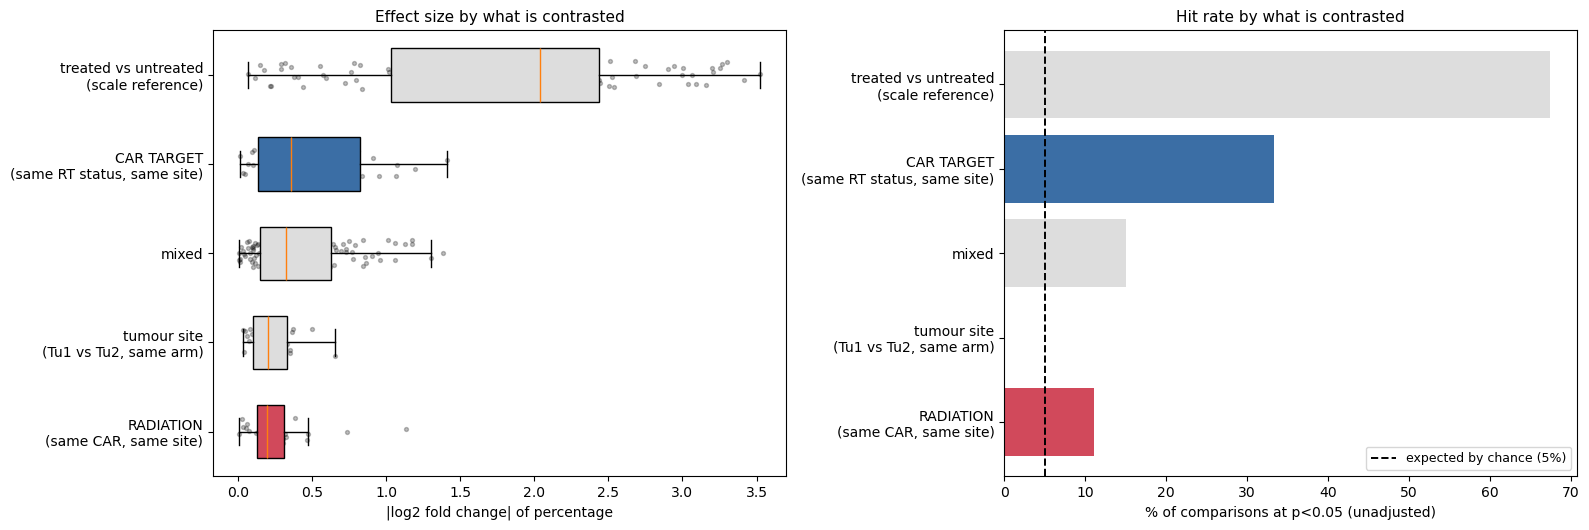

In [13]:
rows = []
for a, b in itertools.combinations(GRPS, 2):
    armA, sA = a.rsplit("_Tu", 1); armB, sB = b.rsplit("_Tu", 1)
    if "NoTx" in (armA, armB):
        kind = "treated vs untreated (scale reference)"
    elif armA == armB:
        kind = "tumour site (Tu1 vs Tu2, same arm)"
    elif armA.replace("RTCy", "").replace("Cy", "") == armB.replace("RTCy", "").replace("Cy", "") \
         and sA == sB:
        kind = "RADIATION (same CAR, same site)"
    elif armA.startswith("RT") == armB.startswith("RT") and sA == sB:
        kind = "CAR TARGET (same RT status, same site)"
    else:
        kind = "mixed"
    ia, ib = meta.index[meta.grp == a], meta.index[meta.grp == b]
    for ct in CTS:
        if min(cnt.loc[ia, ct].min(), cnt.loc[ib, ct].min()) < 20: continue
        pa, pb = prop.loc[ia, ct], prop.loc[ib, ct]
        rows.append(dict(kind=kind, cell_type=ct,
                         abs_log2FC=abs(np.log2(pa.mean()/pb.mean())),
                         p=stats.ttest_ind(lp.loc[ia, ct], lp.loc[ib, ct], equal_var=False)[1]))
Kd = pd.DataFrame(rows)
summ = Kd.groupby("kind").agg(n=("p", "size"), median_abs_log2FC=("abs_log2FC", "median"),
                              mean_abs_log2FC=("abs_log2FC", "mean"),
                              frac_p_lt_05=("p", lambda v: (v < .05).mean()),
                              frac_p_lt_10=("p", lambda v: (v < .10).mean())).round(3)
summ["excess_over_chance"] = (summ.frac_p_lt_05/0.05).round(2)
print("EFFECT SIZE AND HIT RATE BY CONTRAST TYPE (>=20 cells in every sample)")
print(summ.sort_values("median_abs_log2FC", ascending=False).to_string())
summ.to_csv(OUT/"effect_size_by_contrast_type.csv")

order_k = summ.sort_values("median_abs_log2FC").index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))
ax = axes[0]
data = [Kd[Kd.kind == k].abs_log2FC.values for k in order_k]
bp = ax.boxplot(data, vert=False, labels=[k.replace(" (", "\n(") for k in order_k],
                showfliers=False, patch_artist=True, widths=.6)
for patch, k in zip(bp["boxes"], order_k):
    patch.set_facecolor("#d1495b" if "RADIATION" in k else
                        "#3b6ea5" if "CAR TARGET" in k else "#dddddd")
for i, k in enumerate(order_k):
    v = Kd[Kd.kind == k].abs_log2FC.values
    ax.scatter(v, np.full(len(v), i+1) + rng.uniform(-.16, .16, len(v)), s=8, color="k", alpha=.25)
ax.set_xlabel("|log2 fold change| of percentage"); ax.set_title("Effect size by what is contrasted",
                                                                fontsize=11)
ax = axes[1]
ax.barh(range(len(order_k)), [summ.loc[k, "frac_p_lt_05"]*100 for k in order_k],
        color=["#d1495b" if "RADIATION" in k else "#3b6ea5" if "CAR TARGET" in k else "#ddd"
               for k in order_k])
ax.axvline(5, color="k", ls="--", lw=1.4, label="expected by chance (5%)")
ax.set_yticks(range(len(order_k))); ax.set_yticklabels([k.replace(" (", "\n(") for k in order_k])
ax.set_xlabel("% of comparisons at p<0.05 (unadjusted)"); ax.legend(fontsize=9)
ax.set_title("Hit rate by what is contrasted", fontsize=11)
fig.tight_layout(); fig.savefig(FIG/"02b_effect_by_contrast_type.png", dpi=250, bbox_inches="tight")
plt.show()

## 11. Is any of this a sequencing-depth artifact?

Samples range from 483 to 6,449 cells. A rarer population is detected less reliably in a small
sample, which can manufacture a group difference if the groups differ in size. Control: draw the
same number of cells from every sample, recompute, repeat.

In [14]:
n_min = int(cnt.sum(1).min())
print(f"cells per sample: {int(cnt.sum(1).min())} to {int(cnt.sum(1).max())} "
      f"(median {int(cnt.sum(1).median())}) -> downsampling every sample to {n_min}")
print("\ncells per sample by group (is size confounded with arm?):")
print(cnt.sum(1).groupby(meta.grp).agg(["mean", "min", "max"]).round(0).to_string())
_t, p_size = stats.ttest_ind(cnt.sum(1)[meta.RT & (meta.arm != "NoTx")],
                             cnt.sum(1)[~meta.RT & (meta.arm != "NoTx")], equal_var=False)
print(f"\nRT vs non-RT difference in cells recovered: p = {p_size:.3f}")

N_DS = 300
keep = [c for c in CTS if cnt[c].median() >= 15]
res = {c: [] for c in keep}
probs = (cnt.values / cnt.values.sum(1, keepdims=True))
for it in range(N_DS):
    ds = np.vstack([rng.multinomial(n_min, probs[i]) for i in range(len(cnt))])
    ds = pd.DataFrame(ds, index=cnt.index, columns=CTS)
    dp = np.log(ds.div(ds.sum(1), axis=0) + 1e-6)
    for c in keep:
        ia = meta.index[meta.grp == "RTCyPSCA_Tu1"]; ib = meta.index[meta.grp == "CyPSCA_Tu1"]
        res[c].append(stats.ttest_ind(dp.loc[ia, c], dp.loc[ib, c], equal_var=False)[1])
ds_tab = pd.DataFrame({
    "p_observed": [stats.ttest_ind(lp.loc[meta.index[meta.grp == "RTCyPSCA_Tu1"], c],
                                   lp.loc[meta.index[meta.grp == "CyPSCA_Tu1"], c],
                                   equal_var=False)[1] for c in keep],
    "p_downsampled_median": [np.median(res[c]) for c in keep],
    "frac_downsamples_p_lt_10": [np.mean(np.array(res[c]) < 0.10) for c in keep],
}, index=keep).sort_values("p_observed")
ds_tab.to_csv(OUT/"downsampling_check_RTCyPSCA_Tu1_vs_CyPSCA_Tu1.csv")
print(f"\nRTCyPSCA_Tu1 vs CyPSCA_Tu1, {N_DS} equal-depth downsamples of {n_min} cells each")
print(ds_tab.round(3).to_string())
print("\n-> a result that survives is not a depth artifact; one whose p collapses was one.")

cells per sample: 483 to 6441 (median 3486) -> downsampling every sample to 483

cells per sample by group (is size confounded with arm?):
                 mean   min   max
grp                              
CyPSCA_Tu1     3326.0  1836  4319
CyPSCA_Tu2     1873.0   483  3832
CyTAG72_Tu1    4999.0  4691  5307
CyTAG72_Tu2    4073.0  3195  5359
NoTx_Tu1       1386.0   977  1745
NoTx_Tu2       1221.0   960  1646
RTCyPSCA_Tu1   4076.0  3191  5080
RTCyPSCA_Tu2   3256.0  2117  4089
RTCyTAG72_Tu1  5138.0  2814  6441
RTCyTAG72_Tu2  3470.0  2414  4509

RT vs non-RT difference in cells recovered: p = 0.392

RTCyPSCA_Tu1 vs CyPSCA_Tu1, 300 equal-depth downsamples of 483 cells each
                   p_observed  p_downsampled_median  frac_downsamples_p_lt_10
Nonclassical_Mono       0.046                 0.060                     0.760
M1_like_Mac             0.059                 0.088                     0.597
N1_like_Neu             0.082                 0.257                     0.207
Intermediat

## 12. Summary

In [15]:
print("="*100); print("SUMMARY — report these back"); print("="*100)

vt = V[["cart","RT","site","cart x RT","residual (mouse-to-mouse)"]]
print("\n[what explains the variation, mean % across cell types]")
for k, v in vt.mean().sort_values(ascending=False).items(): print(f"    {k:<28s} {v:5.1f}%")
print(f"  cell types where the CAR target explains >25%: "
      f"{V.index[V.cart > 25].tolist()}")
print(f"  cell types where radiation explains  >25%: {V.index[V.RT > 25].tolist() or 'NONE'}")
print(f"  cell types where cart x RT explains  >15%: {V.index[V['cart x RT'] > 15].tolist()}")

print("\n[PERMANOVA, treated samples only]")
for r in [r for r in perm_rows if r["scope"].startswith("treated")]:
    print(f"    {r['factor']:<5s} F={r['F']:5.2f}  R2={r['R2']:.3f}  p={r['p']:.4f}")

print(f"\n[RT effect, are the two CAR backgrounds doing the same thing?]")
print(f"    all cell types  r = {r_all[0]:+.3f} (p={r_all[1]:.3f})")
print(f"    >=50 cells      r = {r_big[0]:+.3f} (p={r_big[1]:.3f})")
print(f"    permutation p={p_perm:.3f}; partial r after baseline removal {pr:+.3f} (p={pp:.3f})")
print(f"    verdict: {INTERACTION_VERDICT}")
print("    defensible wording: do not ASSUME the RT effect points the same way in both CAR")
print("    backgrounds. Section 2's interaction term is the evidence, not this correlation.")
print(f"    ANOVA cross-check: cart x RT explains {vt['cart x RT'].mean():.1f}% of variance on")
print(f"    average vs {vt['RT'].mean():.1f}% for the RT main effect — the interaction is the")
print("    larger of the two, fitted per cell type from all 23 samples.")

print("\n[effect size and hit rate by contrast type]")
for k, r in summ.sort_values("median_abs_log2FC", ascending=False).iterrows():
    print(f"    {k:<42s} median |log2FC| {r.median_abs_log2FC:.2f}   "
          f"p<0.05 in {100*r.frac_p_lt_05:4.1f}% ({r.excess_over_chance:.1f}x chance)")

print("\n[co-variation] pairs of cell types with |r| > 0.6 across treated samples: "
      f"{len(pairs)}")
print(f"  effective independent dimensions (PCs for 80% of variance): "
      f"{int(np.searchsorted(np.cumsum(ev), 80)+1)} of {len(CTS)}")

print("\n[M1_like_Mac, the one RT lead]")
for s in [1, 2]:
    a = pc[(pc.arm == 'RTCyPSCA') & (pc.site == s)][CT]
    b = pc[(pc.arm == 'CyPSCA') & (pc.site == s)][CT]
    pp = stats.ttest_ind(np.log(a), np.log(b), equal_var=False)[1]
    print(f"    PSCA  Tu{s}: {b.mean():5.2f}% -> {a.mean():5.2f}%   p={pp:.3f}"
          f"{'  SEPARATED' if (a.min() > b.max() or a.max() < b.min()) else ''}")
for s in [1, 2]:
    a = pc[(pc.arm == 'RTCyTAG72') & (pc.site == s)][CT]
    b = pc[(pc.arm == 'CyTAG72') & (pc.site == s)][CT]
    pp = stats.ttest_ind(np.log(a), np.log(b), equal_var=False)[1]
    print(f"    TAG72 Tu{s}: {b.mean():5.2f}% -> {a.mean():5.2f}%   p={pp:.3f}")
surv = ds_tab.loc[CT] if CT in ds_tab.index else None
if surv is not None:
    print(f"    equal-depth downsampling: observed p={surv.p_observed:.3f}, "
          f"median p across downsamples {surv.p_downsampled_median:.3f}, "
          f"p<0.10 in {100*surv.frac_downsamples_p_lt_10:.0f}% of draws")

print(f"\n[figures written to {FIG}]")
for f_ in sorted(FIG.glob("02b_*.png")): print(f"  {f_.name}")
print(f"[tables written to {OUT}]")
for f_ in sorted(OUT.glob("*.csv")): print(f"  {f_.name}")
print("="*100)

SUMMARY — report these back

[what explains the variation, mean % across cell types]
    residual (mouse-to-mouse)     72.3%
    cart                          10.3%
    cart x RT                      8.7%
    site                           5.3%
    RT                             3.5%
  cell types where the CAR target explains >25%: ['M1_like_Mac', 'M2_like_Mac']
  cell types where radiation explains  >25%: NONE
  cell types where cart x RT explains  >15%: ['M2_like_Mac', 'Cancer_cell', 'Intermediate_Mac', 'N1_like_Neu', 'N2_like_Neu', 'NKT']

[PERMANOVA, treated samples only]
    arm   F= 1.73  R2=0.215  p=0.0250
    cart  F= 2.41  R2=0.103  p=0.0209
    RT    F= 0.81  R2=0.037  p=0.5972
    site  F= 1.31  R2=0.059  p=0.2219

[RT effect, are the two CAR backgrounds doing the same thing?]
    all cell types  r = -0.275 (p=0.269)
    >=50 cells      r = -0.816 (p=0.025)
    permutation p=0.051; partial r after baseline removal -0.624 (p=0.880)
    verdict: SUGGESTIVE, NOT ESTABLISHED
   